<a href="https://colab.research.google.com/github/dhruvbharija8-lang/ADS-CSE-1/blob/aakriti/ADS_Construction_Cost_Hypothesis_Final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import files
uploaded = files.upload()

Saving ADS_Construction_Dataset_and_Research.zip to ADS_Construction_Dataset_and_Research.zip


In [2]:
import zipfile
import os

# Get the ZIP filename from your upload
zip_name = next(iter(uploaded.keys()))

# Extract the ZIP
with zipfile.ZipFile(zip_name, "r") as z:
    z.extractall("/content")

print("ZIP extracted successfully!")

# Find the actual project folder
for root, dirs, files_list in os.walk("/content"):
    if "construction_permits_ssot.csv.gz" in files_list:
        print("Dataset found at:", os.path.join(root, "construction_permits_ssot.csv.gz"))

ZIP extracted successfully!
Dataset found at: /content/ADS_Construction_Project/data/construction_permits_ssot.csv.gz


In [3]:
import pandas as pd
import os

dataset_path = None

for root, dirs, files_list in os.walk("/content"):
    if "construction_permits_ssot.csv.gz" in files_list:
        dataset_path = os.path.join(
            root, "construction_permits_ssot.csv.gz"
        )
        break

if dataset_path:
    df = pd.read_csv(
        dataset_path,
        compression="gzip",
        low_memory=False
    )

    print("Dataset shape:", df.shape)
    display(df.head())
    df.info()

else:
    print("Dataset not found. Check the extraction output.")

Dataset shape: (154689, 95)


,permit_number,permit_type,permit_type_definition,permit_creation_date,block,lot,street_number,street_number_suffix,street_name,street_suffix,...,invalid_issuance_chronology,has_recorded_issuance,observed_at_least_365_days,issued_within_365_days,building_age_at_filing,building_age_group,estimated_cost_2024_usd_cpi,estimate_revision_usd,estimate_revision_pct,snapshot_date_utc
0,201806081423,8,otc alterations permit,2018-06-08T00:00:00.000,1139,005,167,NaN,Stanyan,Bl,...,True,True,True,NaN,82.0,60-99 years,4910.057341,0.0,0.000000,2026-10-22
1,201812067576,3,additions alterations or repairs,2018-12-06T00:00:00.000,2822A,035,85,NaN,Midcrest,Wy,...,False,True,True,True,57.0,30-59 years,186933.181573,0.0,0.000000,2026-10-22
2,201901029418,8,otc alterations permit,2019-01-02T00:00:00.000,0492,012,2036,NaN,Lombard,St,...,False,True,True,True,60.0,60-99 years,10592.880289,500.0,5.882353,2026-10-22
3,201901029420,8,otc alterations permit,2019-01-02T00:00:00.000,5656,036,69,NaN,Nebraska,St,...,False,True,True,True,49.0,30-59 years,13085.322710,0.0,0.000000,2026-10-22
4,201901029419,8,otc alterations permit,2019-01-02T00:00:00.000,3713,007,1,NaN,Market,St,...,False,True,True,True,40.0,30-59 years,790.104247,0.0,0.000000,2026-10-22


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 154689 entries, 0 to 154688
Data columns (total 95 columns):
 #   Column                                   Non-Null Count   Dtype  
---  ------                                   --------------   -----  
 0   permit_number                            154689 non-null  object 
 1   permit_type                              154689 non-null  int64  
 2   permit_type_definition                   154689 non-null  object 
 3   permit_creation_date                     154689 non-null  object 
 4   block                                    154689 non-null  object 
 5   lot                                      154689 non-null  object 
 6   street_number                            154689 non-null  int64  
 7   street_number_suffix                     1872 non-null    object 
 8   street_name                              154689 non-null  object 
 9   street_suffix                            152427 non-null  object 
 10  unit                            

# ADS Project: Estimated Construction Cost and Permit Waiting Time

## Research question
Do higher-cost construction projects experience longer permit processing times in San Francisco, when comparing permits of similar types filed in the same years?

**Alternative hypothesis (H₁):** Higher estimated project costs are associated with longer permit waiting times, controlling for permit type and filing year.

**Null hypothesis (H₀):** Estimated project cost has no association with permit waiting time after controlling for permit type and filing year.

**Primary outcome:** `filing_to_issuance_days` (calendar days from filing to issuance). This includes both agency and applicant-related time, so it is not a pure measure of government processing time.


## 1. Initial data inspection

In [4]:
print("Dataset dimensions:", df.shape)
display(df.head())
display(df.sample(min(5, len(df)), random_state=42))
df.info()

Dataset dimensions: (154689, 95)


,permit_number,permit_type,permit_type_definition,permit_creation_date,block,lot,street_number,street_number_suffix,street_name,street_suffix,...,invalid_issuance_chronology,has_recorded_issuance,observed_at_least_365_days,issued_within_365_days,building_age_at_filing,building_age_group,estimated_cost_2024_usd_cpi,estimate_revision_usd,estimate_revision_pct,snapshot_date_utc
0,201806081423,8,otc alterations permit,2018-06-08T00:00:00.000,1139,005,167,NaN,Stanyan,Bl,...,True,True,True,NaN,82.0,60-99 years,4910.057341,0.0,0.000000,2026-10-22
1,201812067576,3,additions alterations or repairs,2018-12-06T00:00:00.000,2822A,035,85,NaN,Midcrest,Wy,...,False,True,True,True,57.0,30-59 years,186933.181573,0.0,0.000000,2026-10-22
2,201901029418,8,otc alterations permit,2019-01-02T00:00:00.000,0492,012,2036,NaN,Lombard,St,...,False,True,True,True,60.0,60-99 years,10592.880289,500.0,5.882353,2026-10-22
3,201901029420,8,otc alterations permit,2019-01-02T00:00:00.000,5656,036,69,NaN,Nebraska,St,...,False,True,True,True,49.0,30-59 years,13085.322710,0.0,0.000000,2026-10-22
4,201901029419,8,otc alterations permit,2019-01-02T00:00:00.000,3713,007,1,NaN,Market,St,...,False,True,True,True,40.0,30-59 years,790.104247,0.0,0.000000,2026-10-22


,permit_number,permit_type,permit_type_definition,permit_creation_date,block,lot,street_number,street_number_suffix,street_name,street_suffix,...,invalid_issuance_chronology,has_recorded_issuance,observed_at_least_365_days,issued_within_365_days,building_age_at_filing,building_age_group,estimated_cost_2024_usd_cpi,estimate_revision_usd,estimate_revision_pct,snapshot_date_utc
87198,202202087604,8,otc alterations permit,2022-02-08T00:00:00.000,4030,031,655,NaN,Kansas,St,...,False,True,True,True,58.0,30-59 years,31510.847996,0.0,0.000000,2026-10-22
111476,202302282744,8,otc alterations permit,2023-02-28T00:00:00.000,0239,003,400,NaN,California,St,...,False,True,True,True,116.0,100+ years,260677.464211,0.0,0.000000,2026-10-22
25582,201908280103,8,otc alterations permit,2019-08-28T00:00:00.000,0661,021,2131,NaN,Pine,St,...,False,True,True,True,119.0,100+ years,55020.687330,-30000.0,-66.666667,2026-10-22
86178,202201246545,8,otc alterations permit,2022-01-24T00:00:00.000,7138,012,132,NaN,Sagamore,St,...,False,False,True,False,122.0,100+ years,4462.970867,NaN,NaN,2026-10-22
97328,202207088077,8,otc alterations permit,2022-07-08T00:00:00.000,1763,022,350,NaN,Judah,St,...,False,True,True,True,96.0,60-99 years,50821.072243,0.0,0.000000,2026-10-22


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 154689 entries, 0 to 154688
Data columns (total 95 columns):
 #   Column                                   Non-Null Count   Dtype  
---  ------                                   --------------   -----  
 0   permit_number                            154689 non-null  object 
 1   permit_type                              154689 non-null  int64  
 2   permit_type_definition                   154689 non-null  object 
 3   permit_creation_date                     154689 non-null  object 
 4   block                                    154689 non-null  object 
 5   lot                                      154689 non-null  object 
 6   street_number                            154689 non-null  int64  
 7   street_number_suffix                     1872 non-null    object 
 8   street_name                              154689 non-null  object 
 9   street_suffix                            152427 non-null  object 
 10  unit                            

In [5]:
# Descriptive statistics for numeric columns
display(df.describe().T)

# Missing-value summary
missing = pd.DataFrame({
    "Missing Count": df.isna().sum(),
    "Missing Percentage": (df.isna().mean() * 100).round(2)
}).sort_values("Missing Percentage", ascending=False)

display(missing[missing["Missing Count"] > 0].head(20))

,count,mean,std,min,25%,50%,75%,max
permit_type,154689.0,7.580106e+00,1.367156e+00,1.000000e+00,8.000000e+00,8.000000e+00,8.000000e+00,8.000000e+00
street_number,154689.0,1.112155e+03,1.146372e+03,0.000000e+00,2.250000e+02,6.710000e+02,1.700000e+03,8.400000e+03
unit,20989.0,9.556601e+01,4.086922e+02,0.000000e+00,0.000000e+00,0.000000e+00,2.000000e+00,9.100000e+03
number_of_existing_stories,132732.0,5.637868e+00,8.810979e+00,0.000000e+00,2.000000e+00,3.000000e+00,4.000000e+00,8.800000e+01
number_of_proposed_stories,132174.0,5.689095e+00,8.928586e+00,0.000000e+00,2.000000e+00,3.000000e+00,4.000000e+00,4.790000e+02
estimated_cost,141228.0,1.811986e+05,3.883675e+06,0.000000e+00,5.000000e+03,1.500000e+04,3.868325e+04,4.494670e+08
revised_cost,151695.0,1.308347e+05,2.533660e+06,0.000000e+00,2.000000e+03,1.380000e+04,3.900000e+04,4.494670e+08
existing_units,115614.0,1.620892e+01,6.484221e+01,0.000000e+00,1.000000e+00,1.000000e+00,5.000000e+00,1.907000e+03
proposed_units,116415.0,1.712934e+01,6.590686e+01,0.000000e+00,1.000000e+00,2.000000e+00,6.000000e+00,1.907000e+03
plansets,141804.0,1.126534e+00,9.900195e-01,0.000000e+00,0.000000e+00,2.000000e+00,2.000000e+00,4.000000e+00


,Missing Count,Missing Percentage
voluntary_soft_story_retrofit,154687,100.00
tidf_compliance,154689,100.00
first_construction_document_date,153648,99.33
unit_suffix,152835,98.80
street_number_suffix,152817,98.79
site_permit,152368,98.50
primary_priority,152031,98.28
all_priority_types,152031,98.28
structural_notification,149960,96.94
reroof,137601,88.95


In [6]:
# Check that the required variables exist
relevant_columns = [
    "estimated_cost_2024_usd_cpi",
    "filing_to_issuance_days",
    "filing_to_approval_days",
    "permit_type_definition",
    "filed_year",
    "has_recorded_issuance",
    "invalid_issuance_chronology"
]

for col in relevant_columns:
    print(f"{col}: {'Available' if col in df.columns else 'NOT FOUND'}")

estimated_cost_2024_usd_cpi: Available
filing_to_issuance_days: Available
filing_to_approval_days: Available
permit_type_definition: Available
filed_year: Available
has_recorded_issuance: Available
invalid_issuance_chronology: Available


## 2. Exploratory data analysis (EDA)

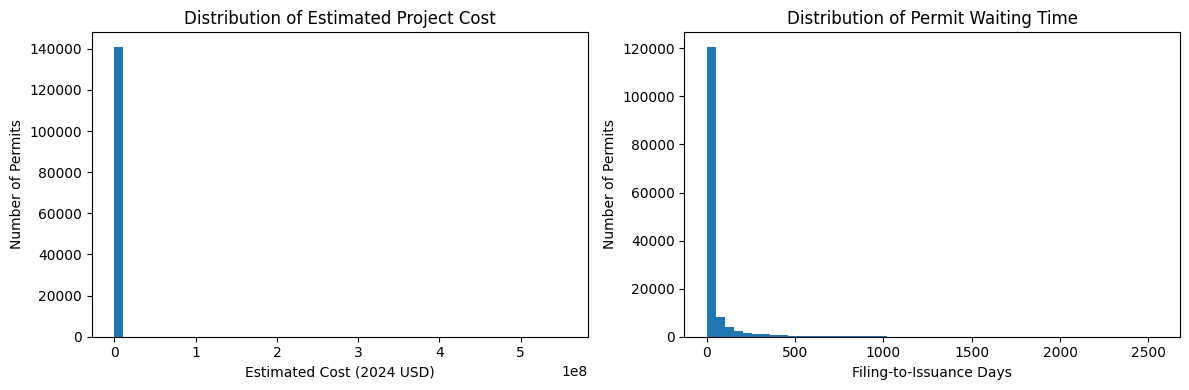

In [7]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(df["estimated_cost_2024_usd_cpi"].dropna(), bins=50)
axes[0].set_title("Distribution of Estimated Project Cost")
axes[0].set_xlabel("Estimated Cost (2024 USD)")
axes[0].set_ylabel("Number of Permits")

axes[1].hist(df["filing_to_issuance_days"].dropna(), bins=50)
axes[1].set_title("Distribution of Permit Waiting Time")
axes[1].set_xlabel("Filing-to-Issuance Days")
axes[1].set_ylabel("Number of Permits")

plt.tight_layout()
plt.show()

In [8]:
# Check duplicates and invalid values; do not automatically delete duplicates
print("Total rows:", len(df))
print("Fully duplicated rows:", df.duplicated().sum())

print("\nRecorded issuance status:")
display(df["has_recorded_issuance"].value_counts(dropna=False))

print("\nInvalid issuance chronology:")
display(df["invalid_issuance_chronology"].value_counts(dropna=False))

print("\nNegative estimated costs:",
      (pd.to_numeric(df["estimated_cost_2024_usd_cpi"], errors="coerce") < 0).sum())
print("Negative waiting times:",
      (pd.to_numeric(df["filing_to_issuance_days"], errors="coerce") < 0).sum())

Total rows: 154689
Fully duplicated rows: 0

Recorded issuance status:


,count
has_recorded_issuance,
True,143218
False,11471



Invalid issuance chronology:


,count
invalid_issuance_chronology,
False,154671
True,18



Negative estimated costs: 0
Negative waiting times: 0


## 3. Prepare the analysis dataset

In [9]:
import numpy as np

analysis = df[[
    "estimated_cost_2024_usd_cpi",
    "filing_to_issuance_days",
    "permit_type_definition",
    "filed_year",
    "has_recorded_issuance",
    "invalid_issuance_chronology"
]].copy()

for col in [
    "estimated_cost_2024_usd_cpi",
    "filing_to_issuance_days",
    "filed_year"
]:
    analysis[col] = pd.to_numeric(analysis[col], errors="coerce")

# Keep permits with recorded issuance and valid chronology.
# Handles Boolean columns and common string representations safely.
recorded = analysis["has_recorded_issuance"].astype(str).str.lower().isin(["true", "1"])
valid_chronology = analysis["invalid_issuance_chronology"].astype(str).str.lower().isin(["false", "0"])

analysis = analysis[recorded & valid_chronology].copy()

analysis = analysis.dropna(subset=[
    "estimated_cost_2024_usd_cpi",
    "filing_to_issuance_days",
    "permit_type_definition",
    "filed_year"
])

analysis = analysis[
    (analysis["estimated_cost_2024_usd_cpi"] >= 0) &
    (analysis["filing_to_issuance_days"] >= 0)
].copy()

analysis["filed_year"] = analysis["filed_year"].astype(int)
analysis["log_cost"] = np.log1p(analysis["estimated_cost_2024_usd_cpi"])

print("Original rows:", len(df))
print("Analysis rows:", len(analysis))
print("Excluded rows:", len(df) - len(analysis))
print("Permit types:", analysis["permit_type_definition"].nunique())
print("Years covered:", sorted(analysis["filed_year"].unique()))

display(analysis[[
    "estimated_cost_2024_usd_cpi",
    "filing_to_issuance_days",
    "log_cost"
]].describe().T)

Original rows: 154689
Analysis rows: 130519
Excluded rows: 24170
Permit types: 8
Years covered: [np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024)]


,count,mean,std,min,25%,50%,75%,max
estimated_cost_2024_usd_cpi,130519.0,129402.250415,2.314126e+06,0.0,5196.345587,15989.708874,40784.966908,2.807616e+08
filing_to_issuance_days,130519.0,48.207127,1.492649e+02,0.0,0.000000,0.000000,25.000000,2.552000e+03
log_cost,130519.0,8.926594,3.187857e+00,0.0,8.555903,9.679763,10.616093,1.945302e+01


## 4. Check zero-day waiting times

In [10]:
zero_count = (analysis["filing_to_issuance_days"] == 0).sum()
zero_pct = (analysis["filing_to_issuance_days"] == 0).mean() * 100

print("Zero-day permits:", zero_count)
print(f"Percentage with zero-day waiting time: {zero_pct:.2f}%")

zero_day_by_type = (
    analysis.groupby("permit_type_definition")
    .agg(
        Permit_Count=("filing_to_issuance_days", "size"),
        Zero_Day_Count=("filing_to_issuance_days",
                        lambda x: (x == 0).sum()),
        Median_Wait_Days=("filing_to_issuance_days", "median")
    )
    .sort_values("Permit_Count", ascending=False)
)

zero_day_by_type["Zero_Day_Percentage"] = (
    zero_day_by_type["Zero_Day_Count"] /
    zero_day_by_type["Permit_Count"] * 100
).round(2)

display(zero_day_by_type.head(20))

Zero-day permits: 68741
Percentage with zero-day waiting time: 52.67%


,Permit_Count,Zero_Day_Count,Median_Wait_Days,Zero_Day_Percentage
permit_type_definition,,,,
otc alterations permit,120431,68166,0.0,56.60
additions alterations or repairs,6830,2,278.0,0.03
sign - erect,2260,484,19.0,21.42
wall or painted sign,320,79,9.0,24.69
demolitions,315,8,154.0,2.54
new construction wood frame,221,0,620.0,0.00
new construction,108,1,528.5,0.93
grade or quarry or fill or excavate,34,1,148.5,2.94


## 5. Compare cost groups within permit type and year

In [11]:
group_size = analysis.groupby(
    ["permit_type_definition", "filed_year"]
)["filing_to_issuance_days"].transform("size")

comparable = analysis[group_size >= 20].copy()

# Assign cost quartiles separately within each permit-type/year group.
def assign_quartiles(x):
    ranks = x.rank(method="first")
    return pd.qcut(
        ranks, q=4,
        labels=["Low", "Medium-low", "Medium-high", "High"]
    )

comparable["cost_quartile"] = comparable.groupby(
    ["permit_type_definition", "filed_year"]
)["estimated_cost_2024_usd_cpi"].transform(assign_quartiles)

quartile_summary = (
    comparable.groupby("cost_quartile", observed=True)
    .agg(
        Permit_Count=("filing_to_issuance_days", "size"),
        Median_Wait_Days=("filing_to_issuance_days", "median"),
        Mean_Wait_Days=("filing_to_issuance_days", "mean"),
        Median_Cost=("estimated_cost_2024_usd_cpi", "median")
    )
)

display(quartile_summary)

,Permit_Count,Median_Wait_Days,Mean_Wait_Days,Median_Cost
cost_quartile,,,,
Low,32622,0.0,39.884403,884.515031
Medium-low,32602,0.0,37.625821,10392.796496
Medium-high,32592,0.0,44.100301,24079.898160
High,32612,12.0,70.421164,77868.217253


## 6. Unadjusted correlation

In [12]:
from scipy.stats import spearmanr

rho, p_corr = spearmanr(
    analysis["estimated_cost_2024_usd_cpi"],
    analysis["filing_to_issuance_days"]
)

print(f"Spearman correlation: {rho:.4f}")
print(f"P-value: {p_corr:.6g}")
print("This correlation is unadjusted; the regression below controls for permit type and filing year.")

Spearman correlation: 0.2401
P-value: 0
This correlation is unadjusted; the regression below controls for permit type and filing year.


## 7. Main hypothesis test: multiple linear regression

In [13]:
%pip -q install statsmodels

In [14]:
import statsmodels.formula.api as smf

model = smf.ols(
    formula="""
        filing_to_issuance_days
        ~ log_cost
        + C(permit_type_definition)
        + C(filed_year)
    """,
    data=analysis
).fit(cov_type="HC1")

print(model.summary())

                               OLS Regression Results                              
Dep. Variable:     filing_to_issuance_days   R-squared:                       0.343
Model:                                 OLS   Adj. R-squared:                  0.343
Method:                      Least Squares   F-statistic:                     720.6
Date:                     Sun, 25 Oct 2026   Prob (F-statistic):               0.00
Time:                             17:56:13   Log-Likelihood:            -8.1109e+05
No. Observations:                   130519   AIC:                         1.622e+06
Df Residuals:                       130505   BIC:                         1.622e+06
Df Model:                               13                                         
Covariance Type:                       HC1                                         
                                                                       coef    std err          z      P>|z|      [0.025      0.975]
---------------------------

In [15]:
beta = model.params["log_cost"]
p_value = model.pvalues["log_cost"]
ci_low, ci_high = model.conf_int().loc["log_cost"]

doubling_effect = beta * np.log(2)
doubling_low = ci_low * np.log(2)
doubling_high = ci_high * np.log(2)

print(f"Cost coefficient: {beta:.4f}")
print(f"P-value: {p_value:.6g}")
print(f"95% confidence interval: [{ci_low:.4f}, {ci_high:.4f}]")
print(f"Estimated days associated with doubling cost: {doubling_effect:.2f}")
print(f"95% CI for doubling-cost estimate: [{doubling_low:.2f}, {doubling_high:.2f}]")

if p_value < 0.05 and beta > 0:
    print("Conclusion: evidence supports a positive association.")
elif p_value < 0.05 and beta < 0:
    print("Conclusion: statistically significant association in the opposite direction.")
else:
    print("Conclusion: insufficient evidence of a nonzero association at the 5% level.")

Cost coefficient: 2.6721
P-value: 1.10164e-133
95% confidence interval: [2.4593, 2.8850]
Estimated days associated with doubling cost: 1.85
95% CI for doubling-cost estimate: [1.70, 2.00]
Conclusion: evidence supports a positive association.


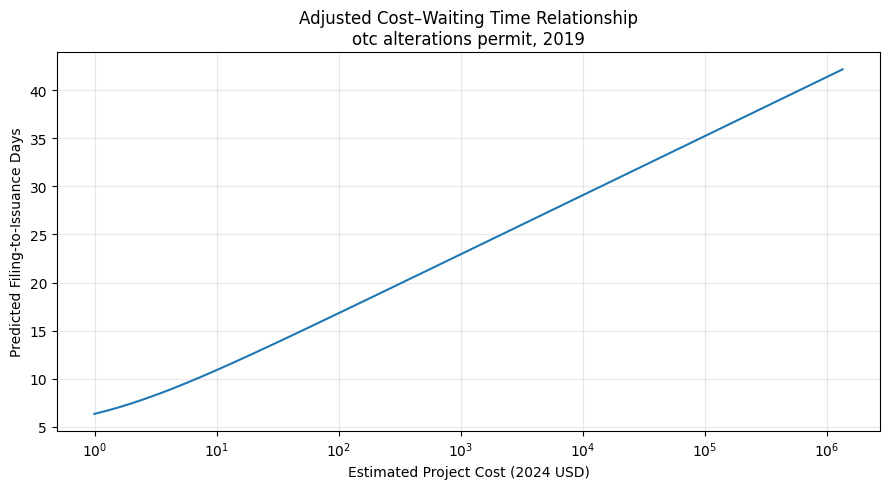

In [16]:
# Adjusted predictions for the most common permit type and filing year
cost_grid = np.linspace(
    analysis["log_cost"].quantile(0.01),
    analysis["log_cost"].quantile(0.99),
    100
)

reference_type = analysis["permit_type_definition"].mode()[0]
reference_year = int(analysis["filed_year"].mode()[0])

prediction_data = pd.DataFrame({
    "log_cost": cost_grid,
    "permit_type_definition": reference_type,
    "filed_year": reference_year
})

predictions = model.predict(prediction_data)

plt.figure(figsize=(9, 5))
plt.plot(np.expm1(cost_grid), predictions)
plt.xscale("symlog", linthresh=1)
plt.xlabel("Estimated Project Cost (2024 USD)")
plt.ylabel("Predicted Filing-to-Issuance Days")
plt.title(f"Adjusted Cost–Waiting Time Relationship\n{reference_type}, {reference_year}")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 8. Robustness check: log-transformed waiting time

In [17]:
analysis["log_wait"] = np.log1p(analysis["filing_to_issuance_days"])

robust_model = smf.ols(
    """
    log_wait
    ~ log_cost
    + C(permit_type_definition)
    + C(filed_year)
    """,
    data=analysis
).fit(cov_type="HC1")

print(robust_model.summary())

robust_beta = robust_model.params["log_cost"]
robust_p = robust_model.pvalues["log_cost"]
robust_ci_low, robust_ci_high = robust_model.conf_int().loc["log_cost"]

print(f"Robustness cost coefficient: {robust_beta:.4f}")
print(f"Robustness p-value: {robust_p:.6g}")
print(f"95% confidence interval: [{robust_ci_low:.4f}, {robust_ci_high:.4f}]")

                            OLS Regression Results                            
Dep. Variable:               log_wait   R-squared:                       0.260
Model:                            OLS   Adj. R-squared:                  0.260
Method:                 Least Squares   F-statistic:                     8784.
Date:                Sun, 25 Oct 2026   Prob (F-statistic):               0.00
Time:                        17:56:15   Log-Likelihood:            -2.5764e+05
No. Observations:              130519   AIC:                         5.153e+05
Df Residuals:                  130505   BIC:                         5.154e+05
Df Model:                          13                                         
Covariance Type:                  HC1                                         
                                                                       coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------

## 9. Export results

In [18]:
results = pd.DataFrame({
    "Metric": [
        "Analysis sample size",
        "Zero-day waiting time percentage",
        "Spearman correlation",
        "Spearman p-value",
        "Main regression cost coefficient",
        "Main regression p-value",
        "Main regression 95% CI lower",
        "Main regression 95% CI upper",
        "Estimated days associated with doubling cost",
        "Main model R-squared",
        "Robustness log-cost coefficient",
        "Robustness p-value",
        "Robustness 95% CI lower",
        "Robustness 95% CI upper"
    ],
    "Value": [
        len(analysis),
        zero_pct,
        rho,
        p_corr,
        beta,
        p_value,
        ci_low,
        ci_high,
        doubling_effect,
        model.rsquared,
        robust_beta,
        robust_p,
        robust_ci_low,
        robust_ci_high
    ]
})

display(results)
results.to_csv("project_cost_hypothesis_results.csv", index=False)
print("Results saved to project_cost_hypothesis_results.csv")

,Metric,Value
0,Analysis sample size,1.305190e+05
1,Zero-day waiting time percentage,5.266743e+01
2,Spearman correlation,2.401465e-01
3,Spearman p-value,0.000000e+00
4,Main regression cost coefficient,2.672125e+00
5,Main regression p-value,1.101643e-133
6,Main regression 95% CI lower,2.459276e+00
7,Main regression 95% CI upper,2.884974e+00
8,Estimated days associated with doubling cost,1.852176e+00
9,Main model R-squared,3.433572e-01


Results saved to project_cost_hypothesis_results.csv


## 10. Report-ready interpretation template

After running all cells, replace the bracketed values below with the values printed by your notebook.

The analysis included **[N]** permits with observed issuance, valid chronology, and complete values for the required variables. Spearman's rank correlation between inflation-adjusted estimated project cost and filing-to-issuance duration was **[rho]** (**p = [p-value]**).

A multiple linear regression controlling for permit type and filing year estimated a coefficient of **[beta]** for log-transformed project cost (95% CI **[lower, upper]**, **p = [p-value]**). The model's R² was **[R²]**. The estimated change associated with doubling project cost was **[days]** calendar days, with a 95% confidence interval of **[lower, upper]** days.

A positive and statistically significant coefficient is evidence consistent with the hypothesis, but does not establish causation. Interpret the results with caution because the analysis excludes permits without recorded issuance and because filing-to-issuance duration includes both agency and applicant-related time. Review the zero-day diagnostic and robustness model before finalizing the conclusion.

### Limitations
- The analysis includes only permits with recorded issuance; permits still awaiting issuance may differ.
- Filing-to-issuance duration includes applicant-related delays as well as agency processing.
- Permit type and year do not control for every potential confounder, such as project complexity.
- The study is observational, so results indicate association rather than causation.
